# 🛠️ **IMPORTS**: Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# 💻 **CÓDIGOS**: Implementação

In [2]:
file_censo = '../data/censo2022/br_ibge_censo_2022_alfabetizacao_grupo_idade_sexo_raca.xlsx'
output_file_csv = '../data/censo2022/dados_alfabetizacao_raca_sexo.csv'

df = pd.read_excel(file_censo)
print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


In [3]:
df['populacao'] = pd.to_numeric(df['populacao'], errors='coerce')

filtro_alfabetizado = df['alfabetizacao'].str.contains('Alfabetizadas', case=False, na=False)

df_alfabetizado = df[filtro_alfabetizado].copy()

# CORRECAO DE ERROS
df_alfabetizado['populacao'].replace(-9999, np.nan, inplace=True)
df_alfabetizado.dropna(subset=['populacao'], inplace=True)

#GRUPOBY RACA SEXO
df_raca_sexo = df_alfabetizado.groupby(['cor_raca', 'sexo'])['populacao'].sum().reset_index()
df_raca_sexo.columns = ['Cor_Raca', 'Sexo', 'Populacao_Alfabetizada']

#GROUP BY RAÇA COM COR
df_raca_total = df_alfabetizado.groupby('cor_raca')['populacao'].sum().reset_index()
df_raca_total.columns = ['Cor_Raca', 'Populacao_Alfabetizada']

print("\n--- População Alfabetizada por Raça/Cor e Sexo (Top 5) ---")
print(df_raca_sexo.sort_values(by='Populacao_Alfabetizada', ascending=False).head())

df_raca_sexo.to_csv(output_file_csv, index=False, encoding='utf-8')
print(f"\nDados agregados exportados para '{output_file_csv}'.")


--- População Alfabetizada por Raça/Cor e Sexo (Top 5) ---
  Cor_Raca      Sexo  Populacao_Alfabetizada
3   Branca  Mulheres              38138157.0
7    Parda  Mulheres              37207974.0
6    Parda    Homens              35107041.0
2   Branca    Homens              33185762.0
8    Preta    Homens               9010965.0

Dados agregados exportados para 'data/dados_alfabetizacao_raca_sexo.csv'.


/tmp/ipykernel_5114/1658167973.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_alfabetizado['populacao'].replace(-9999, np.nan, inplace=True)


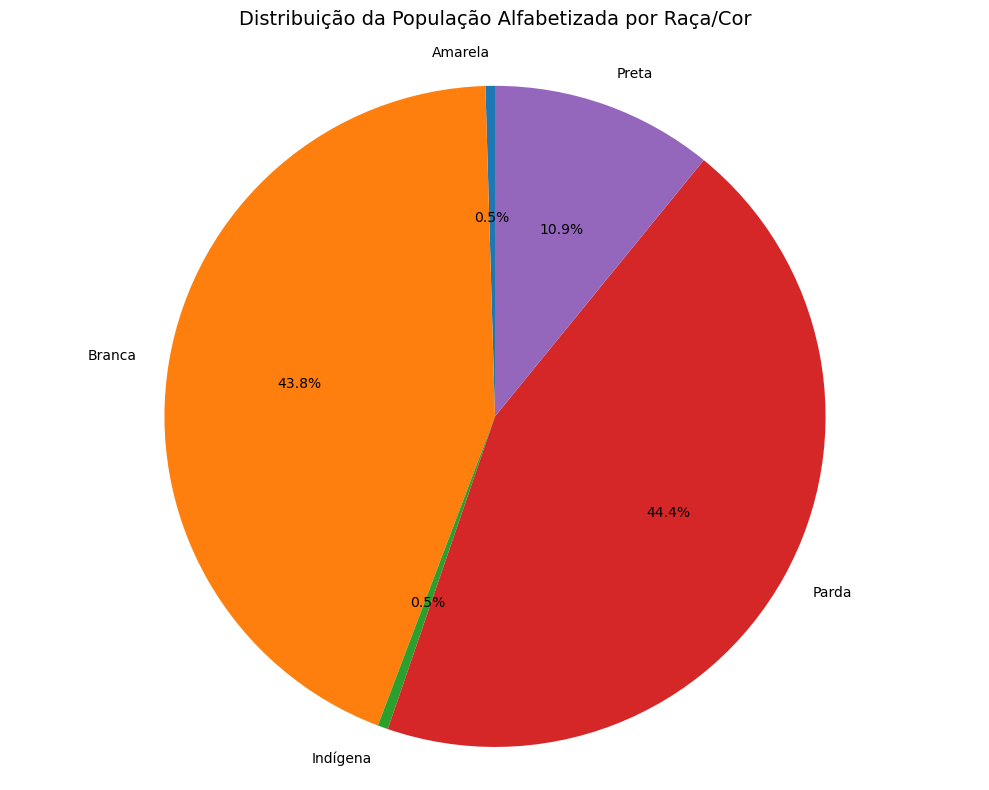

<Figure size 1200x800 with 0 Axes>

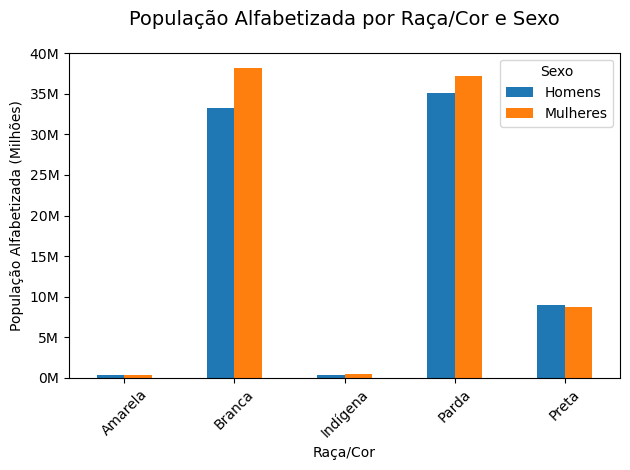

In [4]:
plt.figure(figsize=(10, 8))
wedges, texts, autotexts = plt.pie(
    df_raca_total['Populacao_Alfabetizada'], 
    labels=df_raca_total['Cor_Raca'],
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 10}
)
plt.title('Distribuição da População Alfabetizada por Raça/Cor', fontsize=14, pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 8))

df_pivot = df_raca_sexo.pivot(index='Cor_Raca', columns='Sexo', values='Populacao_Alfabetizada').fillna(0)

df_pivot.plot(kind='bar', color=['#1f77b4', '#ff7f0e']) # Azul para 'Feminino', Laranja para 'Masculino' (padrão)
plt.title('População Alfabetizada por Raça/Cor e Sexo', fontsize=14, pad=20)
plt.xlabel('Raça/Cor')
plt.ylabel('População Alfabetizada (Milhões)')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=45)
plt.legend(title='Sexo')


def millions_formatter(x, pos):
    return f'{x/1e6:,.0f}M'

formatter = FuncFormatter(millions_formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()